In [1]:
#impor packages
import pandas as pd
import numpy as np
from scipy import stats
from scipy.stats import zscore
import matplotlib.pyplot as plt
import seaborn as sns

In [2]:
df_B=pd.read_csv("../data/benin-malanville.csv")
df_B[:2]

,Timestamp,GHI,DNI,DHI,ModA,ModB,Tamb,RH,WS,WSgust,WSstdev,WD,WDstdev,BP,Cleaning,Precipitation,TModA,TModB,Comments
0,2021-08-09 00:01,-1.2,-0.2,-1.1,0.0,0.0,26.2,93.4,0.0,0.4,0.1,122.1,0.0,998,0,0.0,26.3,26.2,NaN
1,2021-08-09 00:02,-1.1,-0.2,-1.1,0.0,0.0,26.2,93.6,0.0,0.0,0.0,0.0,0.0,998,0,0.0,26.3,26.2,NaN


In [3]:
# Convert Timestamp to datetime
df_B['Timestamp'] = pd.to_datetime(df_B['Timestamp'], errors='coerce')
df_B.set_index('Timestamp', inplace=True)

In [4]:
df_B.info()

<class 'pandas.core.frame.DataFrame'>
DatetimeIndex: 525600 entries, 2021-08-09 00:01:00 to 2022-08-09 00:00:00
Data columns (total 18 columns):
 #   Column         Non-Null Count   Dtype  
---  ------         --------------   -----  
 0   GHI            525600 non-null  float64
 1   DNI            525600 non-null  float64
 2   DHI            525600 non-null  float64
 3   ModA           525600 non-null  float64
 4   ModB           525600 non-null  float64
 5   Tamb           525600 non-null  float64
 6   RH             525600 non-null  float64
 7   WS             525600 non-null  float64
 8   WSgust         525600 non-null  float64
 9   WSstdev        525600 non-null  float64
 10  WD             525600 non-null  float64
 11  WDstdev        525600 non-null  float64
 12  BP             525600 non-null  int64  
 13  Cleaning       525600 non-null  int64  
 14  Precipitation  525600 non-null  float64
 15  TModA          525600 non-null  float64
 16  TModB          525600 non-null  float64


In [5]:
df_B.describe()

,GHI,DNI,DHI,ModA,ModB,Tamb,RH,WS,WSgust,WSstdev,WD,WDstdev,BP,Cleaning,Precipitation,TModA,TModB,Comments
count,525600.000000,525600.000000,525600.000000,525600.000000,525600.000000,525600.000000,525600.000000,525600.000000,525600.000000,525600.000000,525600.000000,525600.000000,525600.000000,525600.000000,525600.000000,525600.000000,525600.000000,0.0
mean,240.559452,167.187516,115.358961,236.589496,228.883576,28.179683,54.487969,2.121113,2.809195,0.473390,153.435172,8.582407,994.197199,0.000923,0.001905,35.246026,32.471736,NaN
std,331.131327,261.710501,158.691074,326.894859,316.536515,5.924297,28.073069,1.603466,2.029120,0.273395,102.332842,6.385864,2.474993,0.030363,0.037115,14.807258,12.348743,NaN
min,-12.900000,-7.800000,-12.600000,0.000000,0.000000,11.000000,2.100000,0.000000,0.000000,0.000000,0.000000,0.000000,985.000000,0.000000,0.000000,9.000000,8.100000,NaN
25%,-2.000000,-0.500000,-2.100000,0.000000,0.000000,24.200000,28.800000,1.000000,1.300000,0.400000,59.000000,3.700000,993.000000,0.000000,0.000000,24.200000,23.600000,NaN
50%,1.800000,-0.100000,1.600000,4.500000,4.300000,28.000000,55.100000,1.900000,2.600000,0.500000,181.000000,8.600000,994.000000,0.000000,0.000000,30.000000,28.900000,NaN
75%,483.400000,314.200000,216.300000,463.700000,447.900000,32.300000,80.100000,3.100000,4.100000,0.600000,235.100000,12.300000,996.000000,0.000000,0.000000,46.900000,41.500000,NaN
max,1413.000000,952.300000,759.200000,1342.300000,1342.300000,43.800000,100.000000,19.500000,26.600000,4.200000,360.000000,99.400000,1003.000000,1.000000,2.500000,81.000000,72.500000,NaN


In [6]:
df_B.isnull().sum()

GHI                   0
DNI                   0
DHI                   0
ModA                  0
ModB                  0
Tamb                  0
RH                    0
WS                    0
WSgust                0
WSstdev               0
WD                    0
WDstdev               0
BP                    0
Cleaning              0
Precipitation         0
TModA                 0
TModB                 0
Comments         525600
dtype: int64

In [7]:
df_B.drop_duplicates()

,GHI,DNI,DHI,ModA,ModB,Tamb,RH,WS,WSgust,WSstdev,WD,WDstdev,BP,Cleaning,Precipitation,TModA,TModB,Comments
Timestamp,,,,,,,,,,,,,,,,,,
2021-08-09 00:01:00,-1.2,-0.2,-1.1,0.0,0.0,26.2,93.4,0.0,0.4,0.1,122.1,0.0,998,0,0.0,26.3,26.2,NaN
2021-08-09 00:02:00,-1.1,-0.2,-1.1,0.0,0.0,26.2,93.6,0.0,0.0,0.0,0.0,0.0,998,0,0.0,26.3,26.2,NaN
2021-08-09 00:03:00,-1.1,-0.2,-1.1,0.0,0.0,26.2,93.7,0.3,1.1,0.5,124.6,1.5,997,0,0.0,26.4,26.2,NaN
2021-08-09 00:04:00,-1.1,-0.1,-1.0,0.0,0.0,26.2,93.3,0.2,0.7,0.4,120.3,1.3,997,0,0.0,26.4,26.3,NaN
2021-08-09 00:05:00,-1.0,-0.1,-1.0,0.0,0.0,26.2,93.3,0.1,0.7,0.3,113.2,1.0,997,0,0.0,26.4,26.3,NaN
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
2022-08-08 23:56:00,-5.5,-0.1,-5.9,0.0,0.0,23.1,98.3,0.3,1.1,0.5,119.3,4.1,996,0,0.0,23.5,22.9,NaN
2022-08-08 23:57:00,-5.5,-0.1,-5.8,0.0,0.0,23.1,98.3,0.2,0.7,0.4,115.2,2.3,996,0,0.0,23.5,22.9,NaN
2022-08-08 23:58:00,-5.5,-0.1,-5.8,0.0,0.0,23.1,98.4,0.6,1.1,0.5,129.8,3.4,996,0,0.0,23.5,22.9,NaN


In [8]:
# Missing value report
missing_values = df_B.isna().sum()
print(missing_values[missing_values > 0])

Comments    525600
dtype: int64


In [9]:
# List columns with >5% nulls
threshold = 0.05 * len(df_B)
high_nulls = missing_values[missing_values > threshold]
print("Columns with >5% nulls:", high_nulls.index.tolist())

Columns with >5% nulls: ['Comments']


Outlier Detection & Basic Cleaning

In [10]:
# Outlier Detection & Basic Cleaning
key_cols = ['GHI', 'DNI', 'DHI', 'ModA', 'ModB', 'WS', 'WSgust']
df_z = df_B[key_cols].apply(zscore)
df_B['outlier_flag'] = (np.abs(df_z) > 3).any(axis=1)
print(f"\nNumber of flagged outlier rows: {df_B['outlier_flag'].sum()}")


Number of flagged outlier rows: 7740


In [11]:
country="Benin"
# Impute missing values in key columns with median
for col in key_cols + ['Tamb', 'RH', 'WD', 'BP', 'Cleaning', 'Precipitation', 'TModA', 'TModB']:
    if col in df_B.columns:
        df_B[col].fillna(df_B[col].median(), inplace=True)

# Export cleaned DataFrame (outliers flagged, missings imputed)
clean_path = f'data/{country}_clean.csv'
df_B.to_csv(clean_path, index=True)  # Keep index as Timestamp
print(f"\nCleaned data exported to {clean_path}")


Cleaned data exported to data/Benin_clean.csv


<Figure size 1200x600 with 0 Axes>

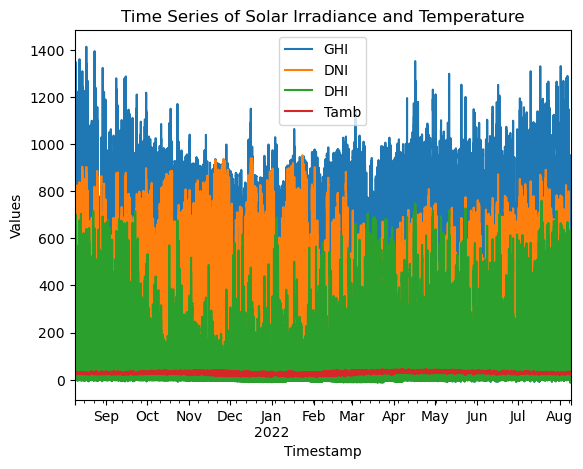

In [12]:
# 3. Time Series Analysis
# Line charts of GHI, DNI, DHI, Tamb vs. Timestamp
plt.figure(figsize=(12, 6))
df_B[['GHI', 'DNI', 'DHI', 'Tamb']].plot()
plt.title('Time Series of Solar Irradiance and Temperature')
plt.xlabel('Timestamp')
plt.ylabel('Values')
plt.show()

<Figure size 1200x600 with 0 Axes>

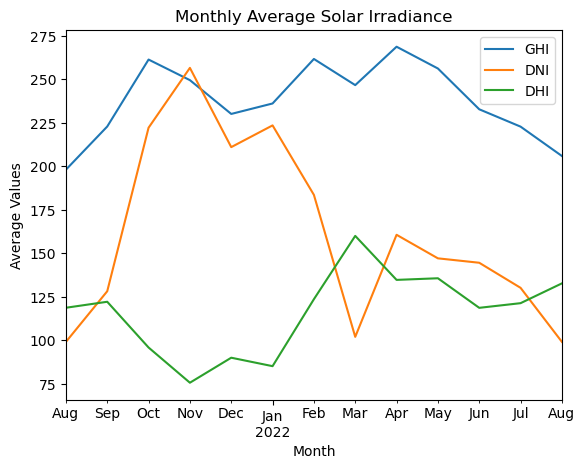

In [13]:
# Monthly patterns
monthly = df_B.resample('M').mean()
plt.figure(figsize=(12, 6))
monthly[['GHI', 'DNI', 'DHI']].plot()
plt.title('Monthly Average Solar Irradiance')
plt.xlabel('Month')
plt.ylabel('Average Values')
plt.show()

<Figure size 1200x600 with 0 Axes>

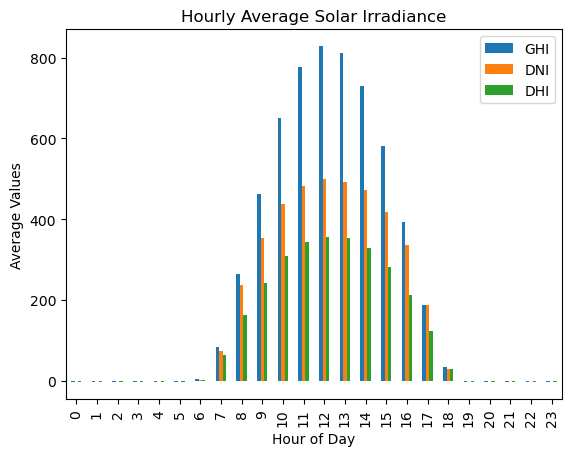

In [14]:
# Daily trends (by hour)
df_B['hour'] = df_B.index.hour
hourly = df_B.groupby('hour').mean()
plt.figure(figsize=(12, 6))
hourly[['GHI', 'DNI', 'DHI']].plot(kind='bar')
plt.title('Hourly Average Solar Irradiance')
plt.xlabel('Hour of Day')
plt.ylabel('Average Values')
plt.show()

<Figure size 800x500 with 0 Axes>

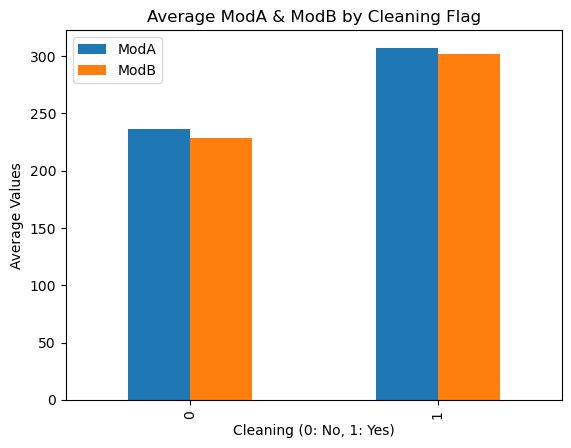

In [15]:
# 4. Cleaning Impact
clean_group = df_B.groupby('Cleaning')[['ModA', 'ModB']].mean()
plt.figure(figsize=(8, 5))
clean_group.plot(kind='bar')
plt.title('Average ModA & ModB by Cleaning Flag')
plt.xlabel('Cleaning (0: No, 1: Yes)')
plt.ylabel('Average Values')
plt.show()

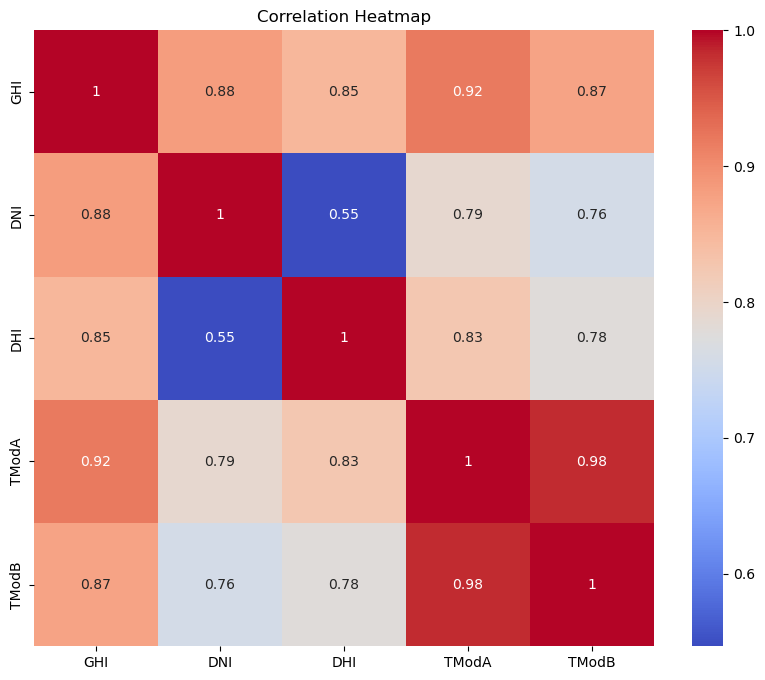

In [16]:
# 5. Correlation & Relationship Analysis
corr_cols = ['GHI', 'DNI', 'DHI', 'TModA', 'TModB']
if all(col in df_B.columns for col in corr_cols):
    corr = df_B[corr_cols].corr()
    plt.figure(figsize=(10, 8))
    sns.heatmap(corr, annot=True, cmap='coolwarm')
    plt.title('Correlation Heatmap')
    plt.show()

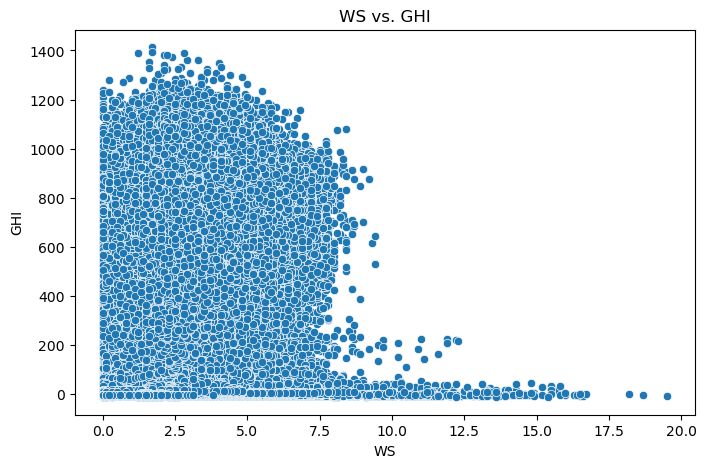

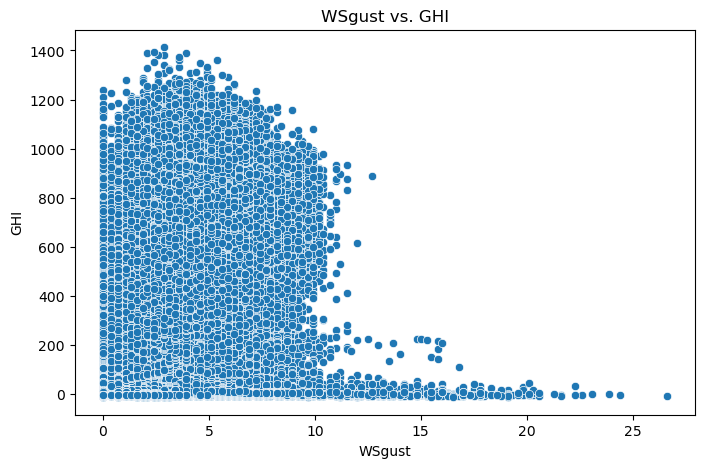

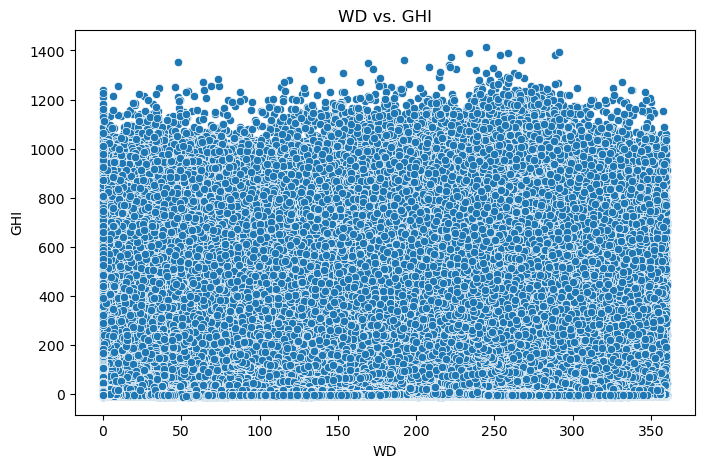

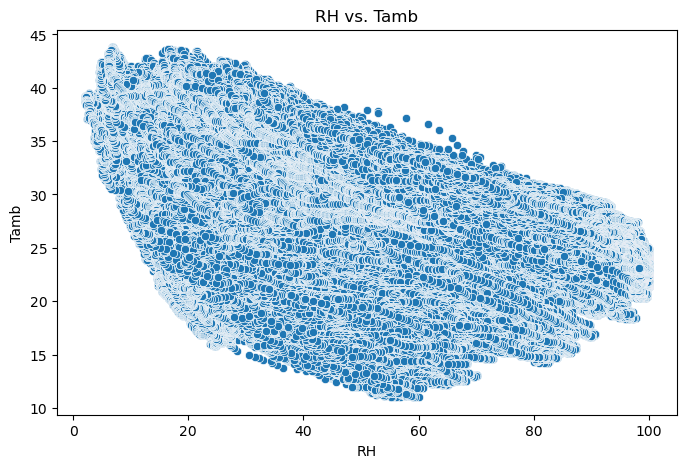

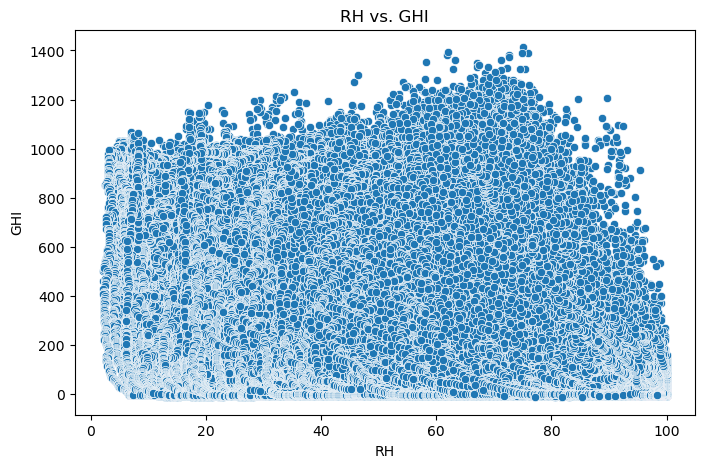

In [17]:
# Scatter plots
plt.figure(figsize=(8, 5))
sns.scatterplot(data=df_B, x='WS', y='GHI')
plt.title('WS vs. GHI')
plt.show()

plt.figure(figsize=(8, 5))
sns.scatterplot(data=df_B, x='WSgust', y='GHI')
plt.title('WSgust vs. GHI')
plt.show()

plt.figure(figsize=(8, 5))
sns.scatterplot(data=df_B, x='WD', y='GHI')
plt.title('WD vs. GHI')
plt.show()

plt.figure(figsize=(8, 5))
sns.scatterplot(data=df_B, x='RH', y='Tamb')
plt.title('RH vs. Tamb')
plt.show()

plt.figure(figsize=(8, 5))
sns.scatterplot(data=df_B, x='RH', y='GHI')
plt.title('RH vs. GHI')
plt.show()

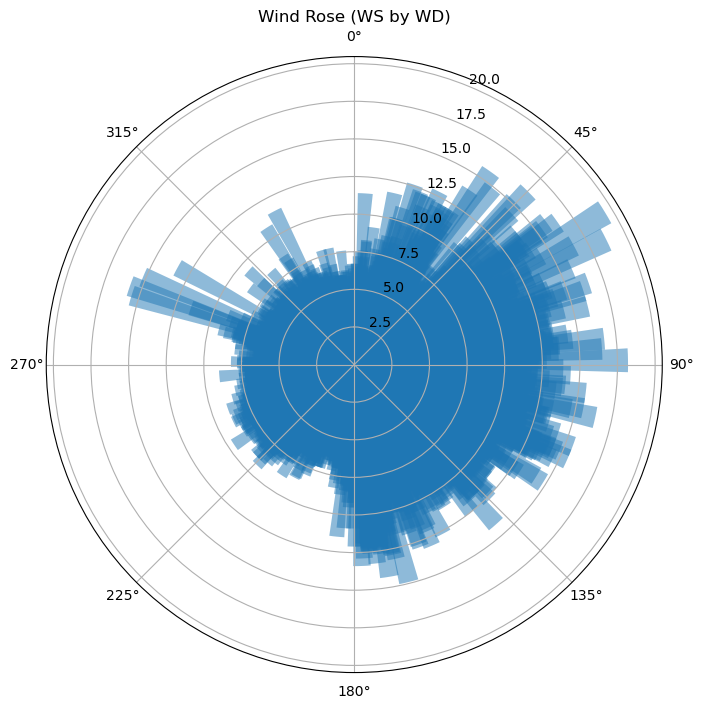

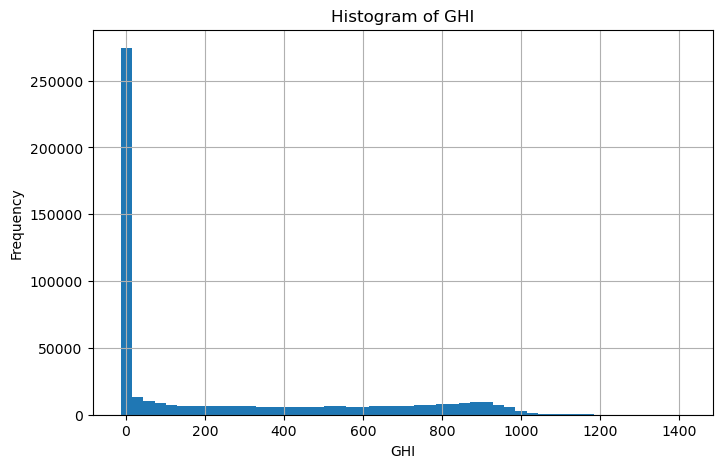

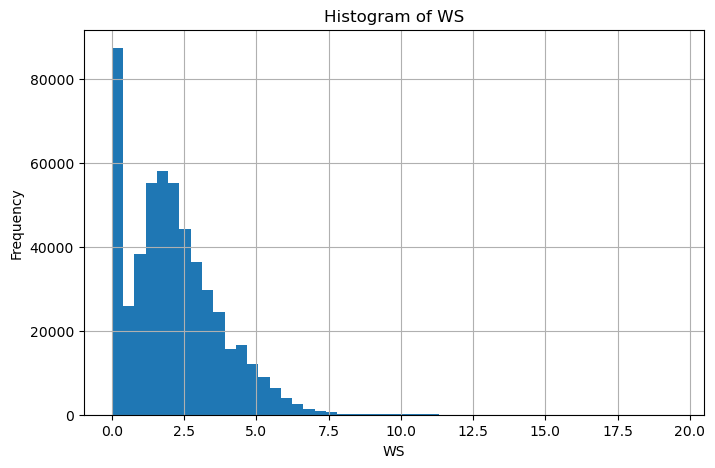

In [18]:
from math import radians
# 6. Wind & Distribution Analysis
# Simple wind rose (polar plot for WD and WS)
plt.figure(figsize=(8, 8))
ax = plt.subplot(111, projection='polar')
ax.bar([radians(w) for w in df_B['WD']], df_B['WS'], width=radians(5), alpha=0.5)
ax.set_theta_direction(-1)
ax.set_theta_zero_location('N')
plt.title('Wind Rose (WS by WD)')
plt.show()

# Histograms
plt.figure(figsize=(8, 5))
df_B['GHI'].hist(bins=50)
plt.title('Histogram of GHI')
plt.xlabel('GHI')
plt.ylabel('Frequency')
plt.show()

plt.figure(figsize=(8, 5))
df_B['WS'].hist(bins=50)
plt.title('Histogram of WS')
plt.xlabel('WS')
plt.ylabel('Frequency')
plt.show()


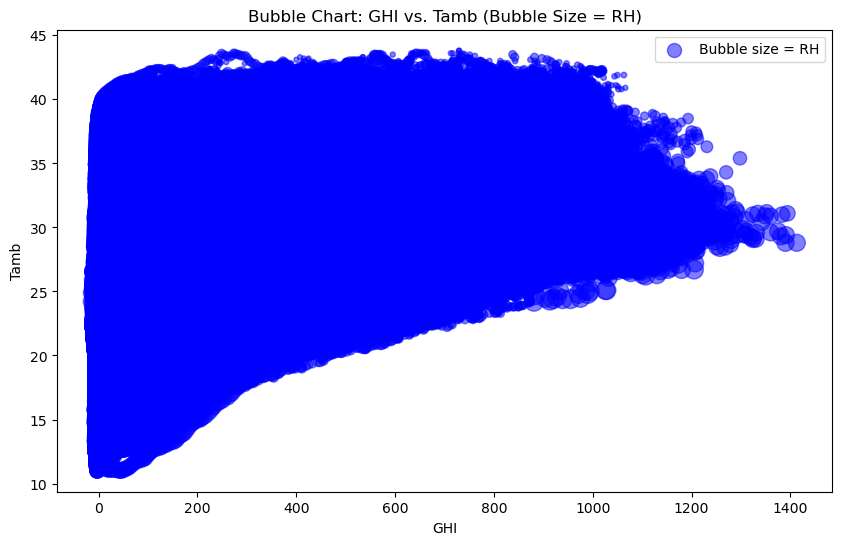

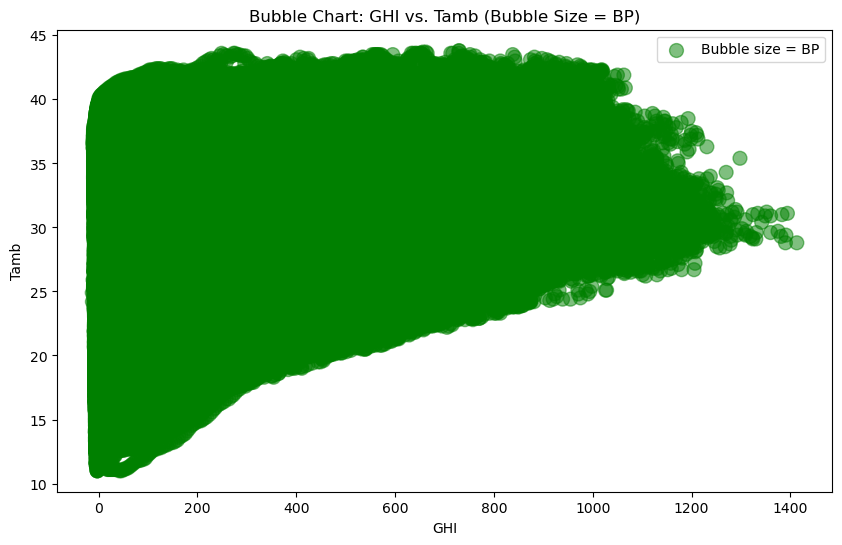

In [19]:
# 7. Temperature Analysis
#  Bubble Chart
plt.figure(figsize=(10, 6))
plt.scatter(df_B['GHI'], df_B['Tamb'], s=df_B['RH'] * 2, alpha=0.5, c='blue', label='Bubble size = RH')  # Scaled size
plt.title('Bubble Chart: GHI vs. Tamb (Bubble Size = RH)')
plt.xlabel('GHI')
plt.ylabel('Tamb')
plt.legend()
plt.show()

# Alternative with BP
plt.figure(figsize=(10, 6))
plt.scatter(df_B['GHI'], df_B['Tamb'], s=df_B['BP'] / 10, alpha=0.5, c='green', label='Bubble size = BP')  # Scaled size
plt.title('Bubble Chart: GHI vs. Tamb (Bubble Size = BP)')
plt.xlabel('GHI')
plt.ylabel('Tamb')
plt.legend()
plt.show()